In [72]:
import os
import glob
from pathlib import Path
import numpy as np
import scipy.io
from scipy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt

# Configuração de estilo sóbrio conforme padrão ABNT / periódicos científicos
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.titlesize': 12,
    'lines.linewidth': 0.8,
    'grid.alpha': 0.5,
    'grid.linestyle': '--'
})

In [73]:
# Definição do ensaio de interesse (aceita "12", 12 ou "B12")
exp = "B17"
exp_id = exp.upper() if str(exp).upper().startswith("B") else f"B{int(exp):02d}"

# Resolução determinística do diretório-raiz do projeto
caminho_atual = Path(os.getcwd())
raiz_projeto = caminho_atual.parent if caminho_atual.name == "notebooks" else caminho_atual

# Estruturação do caminho dos dados brutos de vibração
pasta_exp = raiz_projeto / "data" / "raw_data" / exp_id / "vibrationData"
print(f"Diretório dos dados ({exp_id}): {pasta_exp.resolve()}")

# Varredura determinística de arquivos .mat conforme o padrão de nomenclatura
arquivos_mat = sorted(pasta_exp.glob(f"data_{exp_id}_M*.mat"))
if not arquivos_mat:
    arquivos_mat = sorted(pasta_exp.glob("*.mat"))

if not arquivos_mat:
    raise FileNotFoundError(f"Nenhum arquivo .mat localizado no diretório: {pasta_exp}")

# Seleção dos marcos temporais (início saudável e condição final de falha funcional)
path_saudavel = arquivos_mat[0]
path_falha = arquivos_mat[-5]

print(f"Total de medições encontradas ({exp_id}): {len(arquivos_mat)}")
print(f"Condição saudável inicial: {path_saudavel.name}")
print(f"Falha funcional final:    {path_falha.name}")

Diretório dos dados (B17): E:\Projects\tcc\data\raw_data\B17\vibrationData
Total de medições encontradas (B17): 2733
Condição saudável inicial: data_B17_M00001.mat
Falha funcional final:    data_B17_M02729.mat


In [74]:
def carregar_sinal_paderborn(caminho_arquivo, canal='accHorizFrontal_C', sensibilidade=0.1):
    """
    Extrai o sinal de vibração do arquivo .mat (Aimiyekagbon, 2024), remove o
    offset DC (Wei et al., 2025) e converte a amplitude de Volts para unidades
    de aceleração gravitacional [g].

    Parâmetros:
    -----------
    caminho_arquivo : str ou Path
        Caminho para o arquivo .mat da medição.
    canal : str, padrão='accHorizFrontal_C'
        Chave do acelerômetro ('accHorizFrontal_C' ou 'accHorizRear_A').
    sensibilidade : float, padrão=0.1
        Sensibilidade nominal do sensor PCB 603C01 em V/g (100 mV/g).

    Retorno:
    --------
    sinal_g : np.ndarray
        Vetor unidimensional de aceleração centrado e calibrado em [g].
    """
    dados = scipy.io.loadmat(caminho_arquivo)
    
    if canal in dados:
        sinal = dados[canal].flatten()
    else:
        chaves_validas = [k for k in dados.keys() if not k.startswith('__')]
        sinal = dados[chaves_validas[0]].flatten()
        
    # Remoção do componente de corrente contínua (offset DC de instrumentação)
    sinal_centrado = sinal - np.mean(sinal)
    
    # Conversão de escala: Volts [V] para aceleração gravitacional [g]
    sinal_g = sinal_centrado / sensibilidade
    return sinal_g


def calcular_espectro_amplitude(sinal, fs=64000):
    """
    Computa a FFT unilateral com janelamento de Hanning e restauração de amplitude.
    
    Parâmetros:
    -----------
    sinal : np.ndarray
        Vetor de aceleração calibrado em [g].
    fs : int, padrão=64000
        Frequência de amostragem em Hz.

    Retorno:
    --------
    frequencias : np.ndarray
        Vetor de frequências unilaterais em [Hz].
    espectro_amplitude : np.ndarray
        Espectro de amplitude calibrado na mesma unidade de entrada [g].
    """
    n_pontos = len(sinal)
    janela = np.hanning(n_pontos)
    sinal_janelado = sinal * janela
    
    frequencias = rfftfreq(n_pontos, d=1.0/fs)
    fft_valores = rfft(sinal_janelado)
    
    # Fator de correção de amplitude para a janela de Hanning: 2 / sum(janela)
    espectro_amplitude = (2.0 / np.sum(janela)) * np.abs(fft_valores)
    return frequencias, espectro_amplitude

In [75]:
FS = 64000  # Frequência de amostragem padronizada em 64 kHz (Aimiyekagbon, 2024)
CANAL = 'accHorizFrontal_C'  # Sensor horizontal frontal C

# Carregamento dos vetores de processo
sinal_saudavel = carregar_sinal_paderborn(path_saudavel, canal=CANAL)
sinal_falha = carregar_sinal_paderborn(path_falha, canal=CANAL)

# Vetores da escala temporal
tempo_saudavel = np.arange(len(sinal_saudavel)) / FS
tempo_falha = np.arange(len(sinal_falha)) / FS

# Transformada de Fourier unilateral
freq_saudavel, amp_saudavel = calcular_espectro_amplitude(sinal_saudavel, fs=FS)
freq_falha, amp_falha = calcular_espectro_amplitude(sinal_falha, fs=FS)

print("Processamento de dados concluído com sucesso.")

Processamento de dados concluído com sucesso.


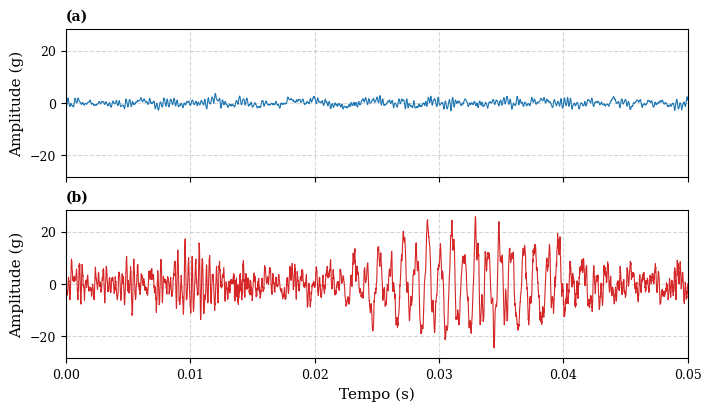

In [76]:
# -------------------------------------------------------------------------
# Sinal de Vibração no Domínio do Tempo – Ensaio {exp_id}
# -------------------------------------------------------------------------
t_lim = 0.05  # Janela de análise de 50 ms para visualização de transitórios

idx_t_h = tempo_saudavel <= t_lim
idx_t_m = tempo_falha <= t_lim

# Determinação do limite simétrico da escala vertical de amplitude (V)
max_amp_t = max(np.max(np.abs(sinal_saudavel[idx_t_h])), 
                np.max(np.abs(sinal_falha[idx_t_m]))) * 1.1

fig_tempo, axs_t = plt.subplots(2, 1, figsize=(7, 4), sharex=True, sharey=True, constrained_layout=True)

# (a) Início do ensaio (Condição saudável)
axs_t[0].plot(tempo_saudavel[idx_t_h], sinal_saudavel[idx_t_h], color='#1f77b4')
axs_t[0].set_title("(a)", loc="left", fontsize=10, weight="bold")
axs_t[0].set_ylabel("Amplitude (g)")
axs_t[0].grid(True)

# (b) Estágio avançado/falha do ensaio
axs_t[1].plot(tempo_falha[idx_t_m], sinal_falha[idx_t_m], color='#d62728')
axs_t[1].set_title("(b)", loc="left", fontsize=10, weight="bold")
axs_t[1].set_xlabel("Tempo (s)")
axs_t[1].set_ylabel("Amplitude (g)")
axs_t[1].grid(True)

# Equalização dos eixos
axs_t[0].set_xlim(0, t_lim)
axs_t[0].set_ylim(-max_amp_t, max_amp_t)

plt.show()

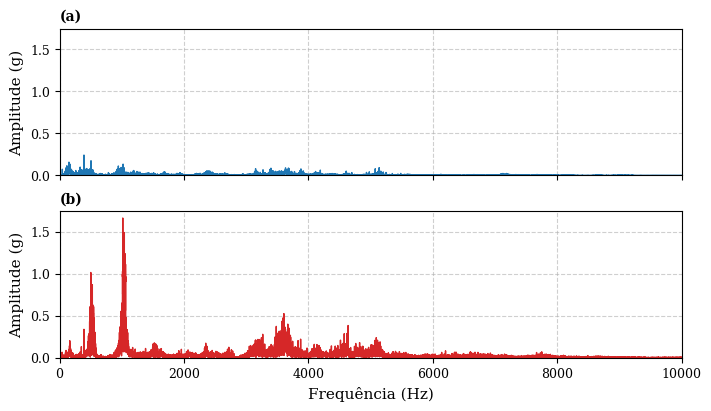

In [77]:
# -------------------------------------------------------------------------
# Espectro de Amplitude Unilateral (FFT) – Ensaio {exp_id}
# -------------------------------------------------------------------------
f_lim = 10000  # Banda de interesse: 0 a 10 kHz

idx_f_h = freq_saudavel <= f_lim
idx_f_m = freq_falha <= f_lim

# Determinação do limite superior da escala de amplitude espectral (V)
max_amp_f = max(np.max(amp_saudavel[idx_f_h]), 
                np.max(amp_falha[idx_f_m])) * 1.05

fig_freq, axs_f = plt.subplots(2, 1, figsize=(7, 4), sharex=True, sharey=True, constrained_layout=True)

# (a) Condição inicial saudável
axs_f[0].plot(freq_saudavel[idx_f_h], amp_saudavel[idx_f_h], color='#1f77b4', linewidth=1)
axs_f[0].set_title('(a)', loc='left', fontsize=10, weight='bold')
axs_f[0].set_ylabel('Amplitude (g)')
axs_f[0].grid(True, linestyle='--', alpha=0.6)

# (b) Estágio avançado de degradação / falha funcional
axs_f[1].plot(freq_falha[idx_f_m], amp_falha[idx_f_m], color='#d62728', linewidth=1)
axs_f[1].set_title('(b)', loc='left', fontsize=10, weight='bold')
axs_f[1].set_xlabel('Frequência (Hz)')
axs_f[1].set_ylabel('Amplitude (g)')
axs_f[1].grid(True, linestyle='--', alpha=0.6)

# Equalização exata das escalas espectrais
axs_f[0].set_xlim(0, f_lim)
axs_f[0].set_ylim(0, max_amp_f)

plt.show()